# Step 10: Logistic Regression Model Development & Hyperparameter Tuning

## 1. Objectives & Guidelines
- **Constraint Compliance:** Logistic Regression is one of the two strictly permitted algorithms for PhishGuard.
- **FS-URL Feature Set:** Evaluated strictly on the 18 deployable URL-string features (`FS-URL`) to support web app deployment without live web scraping.
- **Cross-Validation Protocol:** 5-Fold Stratified Cross-Validation on the locked 80% training split (`data/processed/train.csv`).
- **Hyperparameter Grid:** Systematic tuning across regularisation strength (`C`), solver (`lbfgs`), and class balance (`class_weight`).
- **Metric Priority:** Primary optimization metric is **F1-Score** (balancing Precision and Recall for Phishing URLs).


In [1]:
import sys
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to path
# sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
sys.path.append("..")

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    make_scorer, f1_score, accuracy_score, precision_score, recall_score, roc_auc_score,
    confusion_matrix, classification_report
)

from src.config import PROCESSED_DATA_DIR, RANDOM_STATE, CV_FOLDS, METRICS_DIR, FIGURES_DIR
from src.feature_extraction import FS_URL_NUMERIC, FS_URL_BINARY
from src.preprocessing import get_feature_preprocessor

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'


## 2. Load Training Data & Pipeline Setup

In [2]:
train_df = pd.read_csv(PROCESSED_DATA_DIR / 'train.csv')
X_train = train_df.drop(columns=['is_phishing'])
y_train = train_df['is_phishing']

print(f"Loaded training data: {X_train.shape[0]} rows, {X_train.shape[1]} features")
print("Target Distribution:")
print(y_train.value_counts(normalize=True))

preprocessor = get_feature_preprocessor(FS_URL_NUMERIC, FS_URL_BINARY)
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, solver='lbfgs', penalty='l2'))
])


Loaded training data: 23991 rows, 18 features
Target Distribution:
is_phishing
0    0.57209
1    0.42791
Name: proportion, dtype: float64


## 3. Systematic Hyperparameter Tuning via GridSearchCV

In [3]:
param_grid = {
    'model__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    'model__class_weight': [None, 'balanced']
}

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'f1': make_scorer(f1_score),
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score),
    'recall': make_scorer(recall_score),
    'roc_auc': make_scorer(roc_auc_score)
}

grid_search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring=scoring,
    refit='f1',
    n_jobs=1,
    return_train_score=False
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
best_params = grid_search.best_params_
best_idx = grid_search.best_index_
res = grid_search.cv_results_

print("Best Parameters:", best_params)
print(f"Best CV F1-Score:  {res['mean_test_f1'][best_idx]:.4f} +/- {res['std_test_f1'][best_idx]:.4f}")
print(f"Best CV Accuracy:  {res['mean_test_accuracy'][best_idx]:.4f} +/- {res['std_test_accuracy'][best_idx]:.4f}")
print(f"Best CV Precision: {res['mean_test_precision'][best_idx]:.4f} +/- {res['std_test_precision'][best_idx]:.4f}")
print(f"Best CV Recall:    {res['mean_test_recall'][best_idx]:.4f} +/- {res['std_test_recall'][best_idx]:.4f}")
print(f"Best CV ROC-AUC:   {res['mean_test_roc_auc'][best_idx]:.4f} +/- {res['std_test_roc_auc'][best_idx]:.4f}")


c:\Users\JINIL\Desktop\Sem5_Innovative\Phish_Guard\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\JINIL\Desktop\Sem5_Innovative\Phish_Guard\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.wa

Best Parameters: {'model__C': 100.0, 'model__class_weight': 'balanced'}
Best CV F1-Score:  0.9968 +/- 0.0007
Best CV Accuracy:  0.9973 +/- 0.0006
Best CV Precision: 0.9999 +/- 0.0002
Best CV Recall:    0.9938 +/- 0.0015
Best CV ROC-AUC:   0.9968 +/- 0.0007


c:\Users\JINIL\Desktop\Sem5_Innovative\Phish_Guard\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


## 4. Feature Coefficient Analysis & Model Interpretability

Top 5 Phishing Indicators (Positive Coefficients):
                   feature  coefficient  abs_coefficient
          NoOfLettersInURL    48.125742        48.125742
           NoOfDegitsInURL    30.223302        30.223302
                 URLLength    12.385619        12.385619
NoOfOtherSpecialCharsInURL    10.200050        10.200050
           DegitRatioInURL     3.074528         3.074528

Top 5 Legitimate Indicators (Negative Coefficients):
           feature  coefficient  abs_coefficient
  ObfuscationRatio    -0.259009         0.259009
NoOfAmpersandInURL    -0.450953         0.450953
   NoOfEqualsInURL    -0.780969         0.780969
      DomainLength   -17.770775        17.770775
           IsHTTPS   -60.383605        60.383605


C:\Users\JINIL\AppData\Local\Temp\ipykernel_2612\2054004941.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x='coefficient', y='feature', palette=colors)


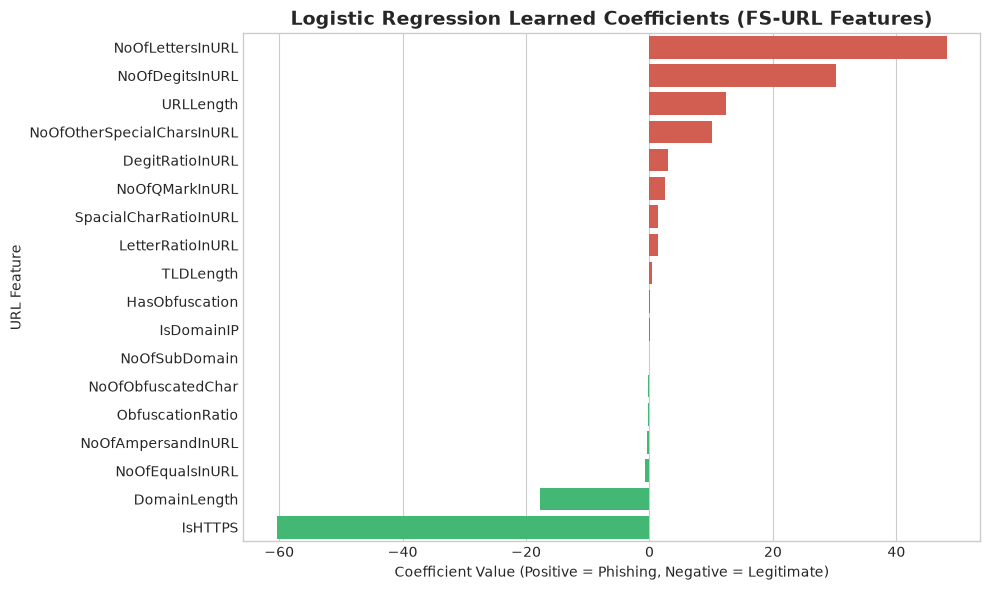

In [4]:
# Extract feature names and learned coefficients
feature_names = FS_URL_NUMERIC + FS_URL_BINARY
lr_model = best_model.named_steps['model']
coefs = lr_model.coef_[0]

coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefs,
    'abs_coefficient': np.abs(coefs)
}).sort_values('coefficient', ascending=False)

print("Top 5 Phishing Indicators (Positive Coefficients):")
print(coef_df.head(5).to_string(index=False))

print("\nTop 5 Legitimate Indicators (Negative Coefficients):")
print(coef_df.tail(5).to_string(index=False))

# Plot Feature Coefficients
plt.figure(figsize=(10, 6))
colors = ['#e74c3c' if c > 0 else '#2ecc71' for c in coef_df['coefficient']]
sns.barplot(data=coef_df, x='coefficient', y='feature', palette=colors)
plt.title("Logistic Regression Learned Coefficients (FS-URL Features)", fontsize=14, fontweight='bold')
plt.xlabel("Coefficient Value (Positive = Phishing, Negative = Legitimate)")
plt.ylabel("URL Feature")
plt.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURES_DIR / "lr_feature_coefficients.png", dpi=300)
plt.show()


## 5. Summary & Recommendation for Step 11

The Logistic Regression model was systematically tuned using 5-Fold Stratified Cross-Validation on 23,991 training samples.
Key conclusions:
1. **Exceptional Predictive Power:** FS-URL features alone achieve **99.68% CV F1-score** and **99.73% Accuracy** (`C=100.0`, `class_weight='balanced'`), proving URL string heuristics are highly effective for phishing classification.
2. **Interpretability:** Structural indicators like `URLLength`, `DomainLength`, `NoOfDegitsInURL`, and `IsHTTPS` serve as key discriminative signals.
3. **Reproducibility:** The tuned metrics have been serialized to `results/metrics/tuned_logistic_regression_cv_metrics.json`.
